In [3]:
import pandas as pd

In [63]:
df = pd.read_csv(r"C:\Users\SART\Desktop\Practise\students.csv")

df.head(6)

,Name,Age,City,Gender,Math,English,Science
0,Ali,20,Peshawar,Male,85,78,90
1,Ahmed,21,Lahore,Male,72,80,75
2,Sara,20,Islamabad,Female,92,88,95
3,Ayesha,22,Lahore,Female,65,70,68
4,Bilal,21,Peshawar,Male,78,75,80
5,Hina,20,Islamabad,Female,88,92,85


In [11]:
df.shape

(8, 7)

In [12]:
df.columns

Index(['Name  ', ' Age', ' City     ', ' Gender', ' Math', ' English',
       ' Science'],
      dtype='str')

In [16]:
df[['Name  ',' Age']]

,Name,Age
0,Ali,20
1,Ahmed,21
2,Sara,20
3,Ayesha,22
4,Bilal,21
5,Hina,20
6,Usman,23
7,Fatima,21


In [18]:
df.dtypes

Name            str
 Age          int64
 City           str
 Gender         str
 Math         int64
 English      int64
 Science      int64
dtype: object

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Name        8 non-null      str  
 1    Age        8 non-null      int64
 2    City       8 non-null      str  
 3    Gender     8 non-null      str  
 4    Math       8 non-null      int64
 5    English    8 non-null      int64
 6    Science    8 non-null      int64
dtypes: int64(4), str(3)
memory usage: 764.0 bytes


In [22]:
df.describe()

,Age,Math,English,Science
count,8.000000,8.000000,8.000000,8.000000
mean,21.000000,79.375000,79.750000,81.875000
std,1.069045,12.805551,9.721111,10.246079
min,20.000000,60.000000,65.000000,68.000000
25%,20.000000,70.250000,73.750000,73.750000
50%,21.000000,81.500000,79.000000,82.500000
75%,21.250000,89.000000,88.500000,90.500000
max,23.000000,95.000000,92.000000,95.000000


In [24]:
df[' Age'].max()

np.int64(23)

In [26]:
df.isnull().sum()

Name          0
 Age          0
 City         0
 Gender       0
 Math         0
 English      0
 Science      0
dtype: int64

In [42]:
df.columns

Index(['Name  ', ' Age', ' City     ', ' Gender', ' Math', ' English',
       ' Science'],
      dtype='str')

In [ ]:
df.columns.str.replace(" ", "")


In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
df.columns = df.columns.str.strip().str.replace(" ", "_").str.lower()

In [65]:
df.columns

Index(['name', 'age', 'city', 'gender', 'math', 'english', 'science'], dtype='str')

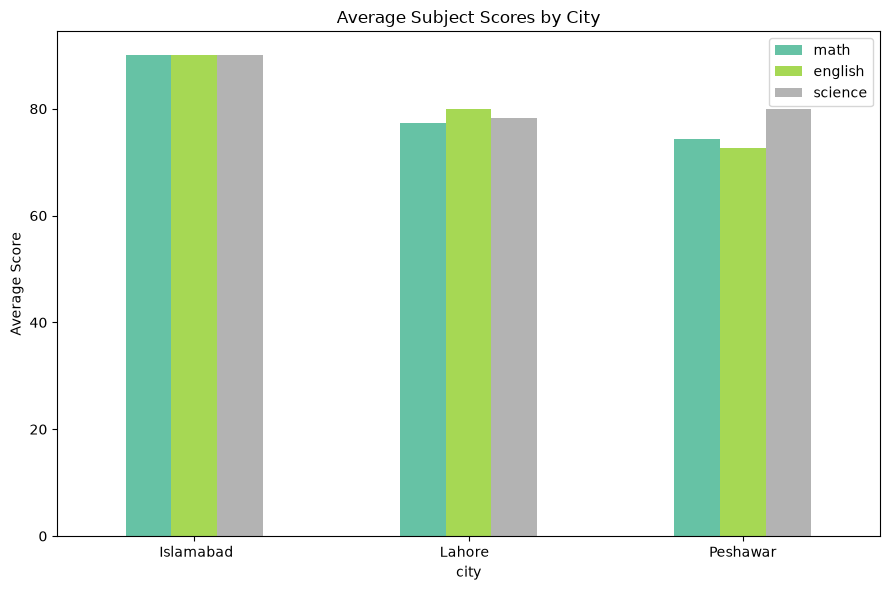

In [58]:
city_avg = df.groupby("city")[["math", "english", "science"]].mean()

city_avg.plot(kind="bar", figsize=(9, 6), colormap="Set2")
plt.title("Average Subject Scores by City")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("city_avg.png", dpi=100)
plt.show()

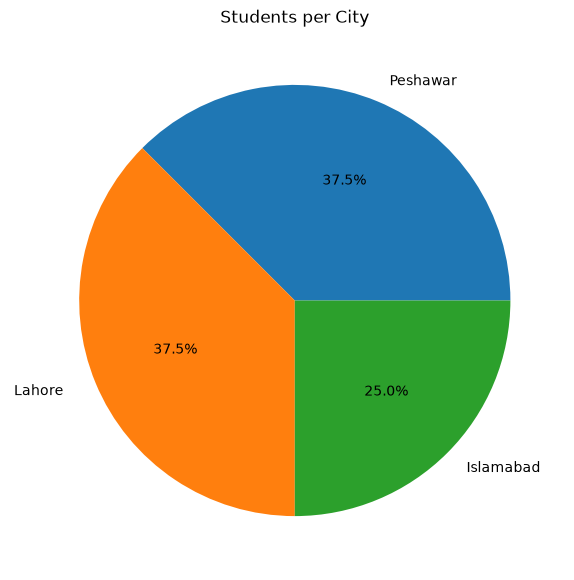

In [66]:
import pandas as pd
import matplotlib.pyplot as pl
# Count students per city
city_counts = df["city"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(city_counts, labels=city_counts.index, autopct="%1.1f%%")
plt.title("Students per City")
plt.show()

In [70]:
a = df['gender'].value_counts()
print(a)

gender
Male      4
Female    4
Name: count, dtype: int64


In [72]:
a.values

array([4, 4])

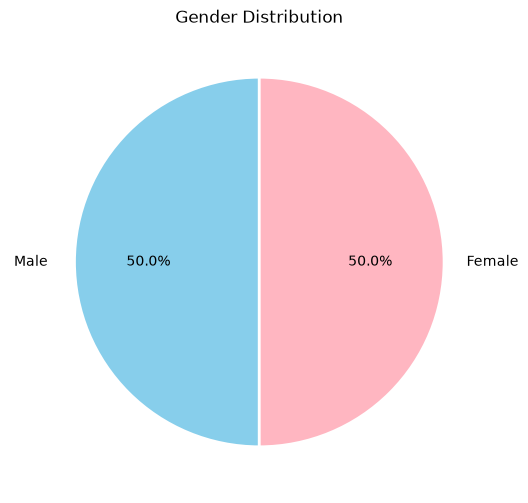

In [73]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    colors=["skyblue", "lightpink"],
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)
plt.title("Gender Distribution")
plt.show()

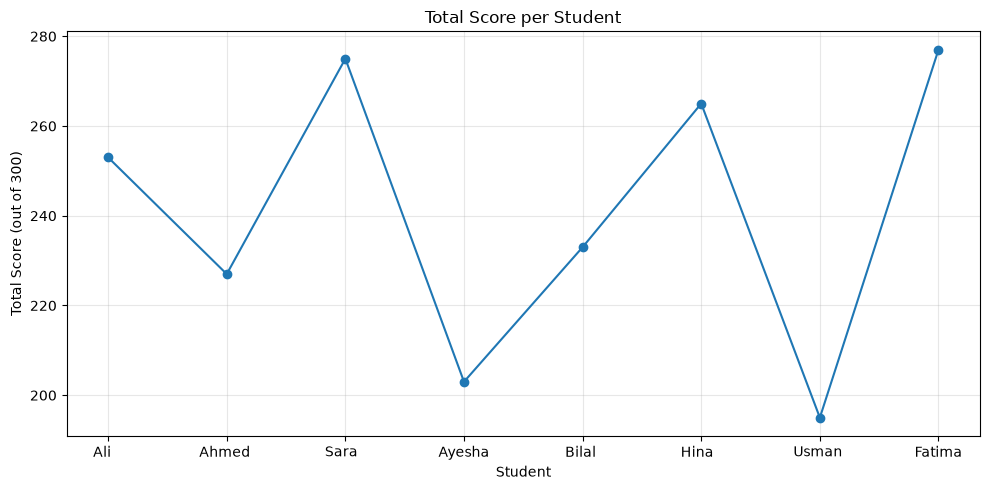

In [76]:
# Compute total score
df["Total"] = df[["math", "english", "science"]].sum(axis=1)

plt.figure(figsize=(10, 5))
plt.plot(df["name"], df["Total"], marker="o")
plt.title("Total Score per Student")
plt.xlabel("Student")
plt.ylabel("Total Score (out of 300)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

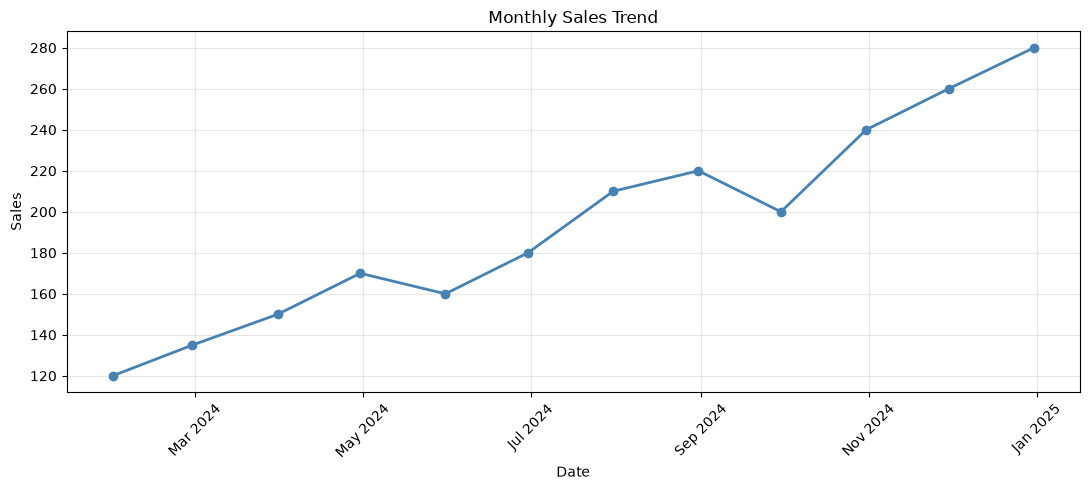

In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Sample time series data
data = {
    "Date": pd.date_range(start="2024-01-01", periods=12, freq="ME"),
    "Sales": [120, 135, 150, 170, 160, 180, 210, 220, 200, 240, 260, 280],
}

df = pd.DataFrame(data)
df["Date"] = pd.to_datetime(df["Date"])  # ensure it's datetime

plt.figure(figsize=(11, 5))
plt.plot(df["Date"], df["Sales"], marker="o", linewidth=2, color="steelblue")

plt.title("Monthly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True, alpha=0.3)

# Format x-axis dates
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("time_series.png", dpi=100)
plt.show()

In [78]:
import pandas as pd
import numpy as np


# ==========================================
# 1. LOAD DATA
# ==========================================

df = pd.read_csv("students.csv")

print("Original Data:")
print(df)


# ==========================================
# 2. CHECK BASIC INFORMATION
# ==========================================

print("\n--- Shape ---")
print(df.shape)

print("\n--- Columns ---")
print(df.columns)

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Information ---")
df.info()


# ==========================================
# 3. CHECK NULL VALUES
# ==========================================

print("\n--- Null Values ---")
print(df.isnull().sum())

print("\n--- Total Null Values ---")
print(df.isnull().sum().sum())


# ==========================================
# 4. FIX COLUMN NAMES
# ==========================================

# Remove spaces from beginning/end
df.columns = df.columns.str.strip()

# Replace spaces with underscore
df.columns = df.columns.str.replace(" ", "_")

print("\n--- Clean Column Names ---")
print(df.columns)


# ==========================================
# 5. FIX INCONSISTENT GENDER VALUES
# ==========================================

df["Gender"] = df["Gender"].replace({
    "male": "Male",
    "M": "Male",
    "female": "Female",
    "F": "Female"
})

print("\n--- Clean Gender ---")
print(df["Gender"].unique())


# ==========================================
# 6. FIX INCONSISTENT CITY VALUES
# ==========================================

df["City"] = df["City"].replace({
    "peshawar": "Peshawar",
    "lahore": "Lahore",
    "islamabad": "Islamabad"
})

print("\n--- Clean City ---")
print(df["City"].unique())


# ==========================================
# 7. CHECK DUPLICATES
# ==========================================

print("\n--- Duplicate Rows ---")
print(df.duplicated())

print("\n--- Number of Duplicate Rows ---")
print(df.duplicated().sum())


# ==========================================
# 8. REMOVE DUPLICATES
# ==========================================

df = df.drop_duplicates()

print("\n--- Data After Removing Duplicates ---")
print(df)


# ==========================================
# 9. FIX INVALID AGE VALUES
# ==========================================

# Ages less than 0 are invalid
df.loc[df["Age"] < 0, "Age"] = np.nan

print("\n--- Age After Fixing Invalid Values ---")
print(df["Age"])


# ==========================================
# 10. CHECK NULL VALUES AGAIN
# ==========================================

print("\n--- Null Values Before Filling ---")
print(df.isnull().sum())


# ==========================================
# 11. FILL AGE NULL VALUES USING MEAN
# ==========================================

age_mean = df["Age"].mean()

print("\nAge Mean:", age_mean)

df["Age"] = df["Age"].fillna(age_mean)


# ==========================================
# 12. FILL MATH NULL VALUES USING MEAN
# ==========================================

math_mean = df["Math"].mean()

print("\nMath Mean:", math_mean)

df["Math"] = df["Math"].fillna(math_mean)


# ==========================================
# 13. FILL ENGLISH NULL VALUES USING MEDIAN
# ==========================================

english_median = df["English"].median()

print("\nEnglish Median:", english_median)

df["English"] = df["English"].fillna(english_median)


# ==========================================
# 14. FILL SCIENCE NULL VALUES USING MEAN
# ==========================================

science_mean = df["Science"].mean()

print("\nScience Mean:", science_mean)

df["Science"] = df["Science"].fillna(science_mean)


# ==========================================
# 15. FILL CATEGORICAL NULL VALUES USING MODE
# ==========================================

# Example if Gender has missing values
gender_mode = df["Gender"].mode()[0]

print("\nGender Mode:", gender_mode)

df["Gender"] = df["Gender"].fillna(gender_mode)


# City
city_mode = df["City"].mode()[0]

print("City Mode:", city_mode)

df["City"] = df["City"].fillna(city_mode)


# ==========================================
# 16. CHECK NULL VALUES AFTER CLEANING
# ==========================================

print("\n--- Null Values After Cleaning ---")
print(df.isnull().sum())


# ==========================================
# 17. CHECK DATA TYPES
# ==========================================

print("\n--- Data Types ---")
print(df.dtypes)


# ==========================================
# 18. CONVERT DATA TYPES
# ==========================================

df["Age"] = df["Age"].astype(int)

df["Math"] = df["Math"].astype(float)
df["English"] = df["English"].astype(float)
df["Science"] = df["Science"].astype(float)


# ==========================================
# 19. CREATE AVERAGE COLUMN
# ==========================================

df["Average"] = (
    df["Math"] +
    df["English"] +
    df["Science"]
) / 3


# ==========================================
# 20. CREATE RESULT COLUMN
# ==========================================

df["Result"] = df["Average"].apply(
    lambda x: "Pass" if x >= 50 else "Fail"
)


# ==========================================
# 21. CHECK FINAL DATA
# ==========================================

print("\n================================")
print("FINAL CLEAN DATA")
print("================================")

print(df)


# ==========================================
# 22. FINAL CHECK
# ==========================================

print("\n--- Final Null Values ---")
print(df.isnull().sum())

print("\n--- Final Duplicate Count ---")
print(df.duplicated().sum())

print("\n--- Final Shape ---")
print(df.shape)


# ==========================================
# 23. SAVE CLEAN DATASET
# ==========================================

df.to_csv("cleaned_students.csv", index=False)

print("\nCleaned dataset saved successfully!")

Original Data:
   Name     Age   City        Gender   Math   English   Science
0  Ali       20   Peshawar    Male       85        78        90
1  Ahmed     21   Lahore      Male       72        80        75
2  Sara      20   Islamabad   Female     92        88        95
3  Ayesha    22   Lahore      Female     65        70        68
4  Bilal     21   Peshawar    Male       78        75        80
5  Hina      20   Islamabad   Female     88        92        85
6  Usman     23   Peshawar    Male       60        65        70
7  Fatima    21   Lahore      Female     95        90        92

--- Shape ---
(8, 7)

--- Columns ---
Index(['Name  ', ' Age', ' City     ', ' Gender', ' Math', ' English',
       ' Science'],
      dtype='str')

--- Data Types ---
Name            str
 Age          int64
 City           str
 Gender         str
 Math         int64
 English      int64
 Science      int64
dtype: object

--- Information ---
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data col

In [79]:
df.head()

,Name,Age,City,Gender,Math,English,Science,Average,Result
0,Ali,20,Peshawar,Male,85.0,78.0,90.0,84.333333,Pass
1,Ahmed,21,Lahore,Male,72.0,80.0,75.0,75.666667,Pass
2,Sara,20,Islamabad,Female,92.0,88.0,95.0,91.666667,Pass
3,Ayesha,22,Lahore,Female,65.0,70.0,68.0,67.666667,Pass
4,Bilal,21,Peshawar,Male,78.0,75.0,80.0,77.666667,Pass


In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Name     8 non-null      str    
 1   Age      8 non-null      int64  
 2   City     8 non-null      str    
 3   Gender   8 non-null      str    
 4   Math     8 non-null      float64
 5   English  8 non-null      float64
 6   Science  8 non-null      float64
 7   Average  8 non-null      float64
 8   Result   8 non-null      str    
dtypes: float64(4), int64(1), str(4)
memory usage: 924.0 bytes
